# Books Market Analysis

## Objective
To scrape book data from Books to Scrape, clean and analyze the data,
and generate useful business insights and recommendations.

# STEP 2 — Import libraries

In [2]:
%pip install pandas requests beautifulsoup4 matplotlib seaborn

   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.8 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.8 MB 2.6 MB/s eta 0:00:04
   ----- ---------------------------------- 1.3/9.8 MB 1.9 MB/s eta 0:00:05
   ----- ---------------------------------- 1.3/9.8 MB 1.9 MB/s eta 0:00:05
   ------- -------------------------------- 1.8/9.8 MB 1.7 MB/s eta 0:00:05
   ------- -------------------------------- 1.8/9.8 MB 1.7 MB/s eta 0:00:05
   --------- ------------------------------ 2.4/9.8 MB 1.5 MB/s eta 0:00:05
   ---------- ----------------------------- 2.6/9.8 MB 1.6 MB/s eta 0:00:05
   ------------ --------------------------- 3.1/9.8 MB 1.6 MB/s eta 0:00:05
   ------------- -------------------------- 3.4/9.8 MB 1.6 MB/s eta 0:00:04
   ---------------- ----------------------- 3.9/9.8 MB 1.7 MB/s eta 0:00:04
   ---------------- ----------------------- 3.9/9.8 MB 1.7 MB/s eta 0:00:04
   ----------------- -----

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [3]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

# STEP 3 — Test the website

In [4]:
url = "https://books.toscrape.com/"

response = requests.get(url)

print(response.status_code)

200


# STEP 4 — Scrape books from multiple pages 📚

In [5]:
base_url = "https://books.toscrape.com/catalogue/page-{}.html"

books = []

for page in range(1, 51):
    url = base_url.format(page)
    
    response = requests.get(url)
    soup = BeautifulSoup(response.text, "html.parser")
    
    book_items = soup.find_all("article", class_="product_pod")
    
    for book in book_items:
        title = book.h3.a["title"]
        price = book.find("p", class_="price_color").text.strip()
        availability = book.find("p", class_="instock availability").text.strip()
        rating = book.find("p", class_="star-rating")["class"][1]
        
        books.append({
            "Title": title,
            "Price": price,
            "Availability": availability,
            "Rating": rating
        })

print("Total books scraped:", len(books))

Total books scraped: 1000


# STEP 5 — Convert to DataFrame

In [6]:
df = pd.DataFrame(books)

df.head()

,Title,Price,Availability,Rating
0,A Light in the Attic,Â£51.77,In stock,Three
1,Tipping the Velvet,Â£53.74,In stock,One
2,Soumission,Â£50.10,In stock,One
3,Sharp Objects,Â£47.82,In stock,Four
4,Sapiens: A Brief History of Humankind,Â£54.23,In stock,Five


# STEP 6 — Check the dataset

In [7]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.info()

Rows: 1000
Columns: 4
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Title         1000 non-null   str  
 1   Price         1000 non-null   str  
 2   Availability  1000 non-null   str  
 3   Rating        1000 non-null   str  
dtypes: str(4)
memory usage: 31.4 KB


# STEP 7 — Save Scraped Dataset

In [8]:
df.to_csv("scraped_books.csv", index=False)

print("Scraped dataset saved successfully!")

Scraped dataset saved successfully!


In [9]:
import os

print(os.path.exists("scraped_books.csv"))

True


# STEP 8 — Data Cleaning

# 8.1 Create a copy

In [10]:
cleaned_df = df.copy()

print("Cleaning started...")

Cleaning started...


# 8.2 Check missing values

In [11]:
cleaned_df.isnull().sum()

Title           0
Price           0
Availability    0
Rating          0
dtype: int64

# 8.3 Remove duplicate books

In [12]:
print("Duplicates before:", cleaned_df.duplicated().sum())

cleaned_df = cleaned_df.drop_duplicates()

print("Duplicates after:", cleaned_df.duplicated().sum())

Duplicates before: 0
Duplicates after: 0


# 8.4 Clean Price using Regex 💰

In [13]:
cleaned_df["Price"] = cleaned_df["Price"].str.replace(r"[^\d.]", "", regex=True)

cleaned_df["Price"] = pd.to_numeric(cleaned_df["Price"])

In [14]:
cleaned_df["Price"].head()

0    51.77
1    53.74
2    50.10
3    47.82
4    54.23
Name: Price, dtype: float64

# 8.5 Clean Availability using Regex 📦

In [15]:
cleaned_df["Availability"] = cleaned_df["Availability"].str.extract(r"(In stock|Out of stock)", expand=False)

In [16]:
cleaned_df["Availability"].value_counts()

Availability
In stock    1000
Name: count, dtype: int64

# 8.6 Convert Rating from words to numbers ⭐

In [17]:
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

cleaned_df["Rating"] = cleaned_df["Rating"].map(rating_map)

In [18]:
cleaned_df["Rating"].value_counts().sort_index()

Rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

# 8.7 Create 5 Regex-based cleaning/extraction tasks

In [19]:
# Regex Task 1 - Extract numeric price
cleaned_df["Price"] = cleaned_df["Price"].astype(str).str.extract(r"(\d+\.?\d*)")[0].astype(float)

# Regex Task 2 - Extract stock status
cleaned_df["Availability"] = cleaned_df["Availability"].str.extract(r"(In stock|Out of stock)", expand=False)

# Regex Task 3 - Clean extra spaces from title
cleaned_df["Title"] = cleaned_df["Title"].str.replace(r"\s+", " ", regex=True).str.strip()

# Regex Task 4 - Remove unwanted special characters from title
cleaned_df["Title"] = cleaned_df["Title"].str.replace(r"[^\w\s:,.'!?-]", "", regex=True)

# Regex Task 5 - Extract first word from title
cleaned_df["Title_First_Word"] = cleaned_df["Title"].str.extract(r"^(\w+)", expand=False)

print("5 Regex cleaning/extraction tasks completed!")

5 Regex cleaning/extraction tasks completed!


# STEP 8.8 — Check the cleaned data

In [20]:
cleaned_df.head()

,Title,Price,Availability,Rating,Title_First_Word
0,A Light in the Attic,51.77,In stock,3,A
1,Tipping the Velvet,53.74,In stock,1,Tipping
2,Soumission,50.10,In stock,1,Soumission
3,Sharp Objects,47.82,In stock,4,Sharp
4,Sapiens: A Brief History of Humankind,54.23,In stock,5,Sapiens


In [21]:
cleaned_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Title             1000 non-null   str    
 1   Price             1000 non-null   float64
 2   Availability      1000 non-null   str    
 3   Rating            1000 non-null   int64  
 4   Title_First_Word  999 non-null    str    
dtypes: float64(1), int64(1), str(3)
memory usage: 39.2 KB


# STEP 9 — Feature Engineering

In [22]:
# Feature 1: Price Category
def price_category(price):
    if price < 20:
        return "Budget"
    elif price < 40:
        return "Mid-Range"
    else:
        return "Premium"

cleaned_df["Price_Category"] = cleaned_df["Price"].apply(price_category)


# Feature 2: Rating Category
def rating_category(rating):
    if rating >= 4:
        return "Highly Rated"
    elif rating >= 3:
        return "Average Rated"
    else:
        return "Low Rated"

cleaned_df["Rating_Category"] = cleaned_df["Rating"].apply(rating_category)


# Feature 3: Availability Flag
cleaned_df["Availability_Flag"] = cleaned_df["Availability"].apply(
    lambda x: 1 if x == "In stock" else 0
)


# Feature 4: Title Length
cleaned_df["Title_Length"] = cleaned_df["Title"].str.len()

print("Feature engineering completed!")

Feature engineering completed!


In [23]:
cleaned_df.head()

,Title,Price,Availability,Rating,Title_First_Word,Price_Category,Rating_Category,Availability_Flag,Title_Length
0,A Light in the Attic,51.77,In stock,3,A,Premium,Average Rated,1,20
1,Tipping the Velvet,53.74,In stock,1,Tipping,Premium,Low Rated,1,18
2,Soumission,50.10,In stock,1,Soumission,Premium,Low Rated,1,10
3,Sharp Objects,47.82,In stock,4,Sharp,Premium,Highly Rated,1,13
4,Sapiens: A Brief History of Humankind,54.23,In stock,5,Sapiens,Premium,Highly Rated,1,37


In [25]:
cleaned_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Title              1000 non-null   str    
 1   Price              1000 non-null   float64
 2   Availability       1000 non-null   str    
 3   Rating             1000 non-null   int64  
 4   Title_First_Word   999 non-null    str    
 5   Price_Category     1000 non-null   str    
 6   Rating_Category    1000 non-null   str    
 7   Availability_Flag  1000 non-null   int64  
 8   Title_Length       1000 non-null   int64  
dtypes: float64(1), int64(3), str(5)
memory usage: 70.4 KB


In [26]:
print(cleaned_df["Price_Category"].value_counts())
print()
print(cleaned_df["Rating_Category"].value_counts())

Price_Category
Premium      403
Mid-Range    401
Budget       196
Name: count, dtype: int64

Rating_Category
Low Rated        422
Highly Rated     375
Average Rated    203
Name: count, dtype: int64


# STEP 10 — Save Cleaned Dataset

In [27]:
cleaned_df.to_csv("cleaned_books.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [28]:
import os

print(os.path.exists("cleaned_books.csv"))

True


# STEP 11 — Basic EDA 📊

In [29]:
cleaned_df.describe()

,Price,Rating,Availability_Flag,Title_Length
count,1000.00000,1000.000000,1000.0,1000.000000
mean,35.07035,2.923000,1.0,38.018000
std,14.44669,1.434967,0.0,25.595093
min,10.00000,1.000000,1.0,2.000000
25%,22.10750,2.000000,1.0,18.000000
50%,35.98000,3.000000,1.0,32.000000
75%,47.45750,4.000000,1.0,51.250000
max,59.99000,5.000000,1.0,204.000000


In [30]:
cleaned_df["Price"].describe()

count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: Price, dtype: float64

In [31]:
cleaned_df["Rating"].value_counts().sort_index()

Rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

# STEP 12 — Price Distribution

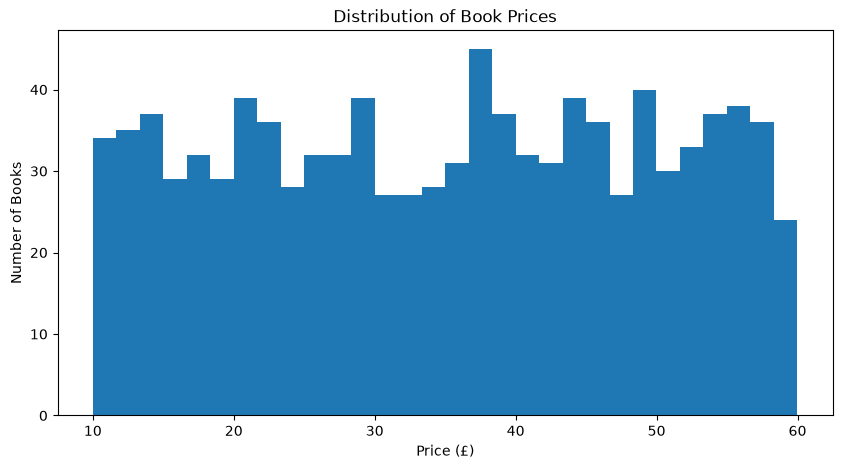

In [32]:
plt.figure(figsize=(10, 5))

plt.hist(cleaned_df["Price"], bins=30)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")

plt.show()

# STEP 12 — Chart 2: Rating Distribution ⭐

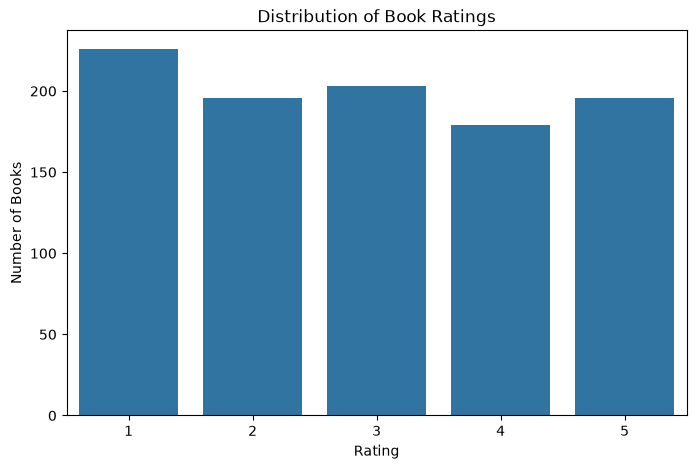

In [33]:
plt.figure(figsize=(8, 5))

sns.countplot(x="Rating", data=cleaned_df)

plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Books")

plt.show()

# STEP 13 — Price Category Distribution

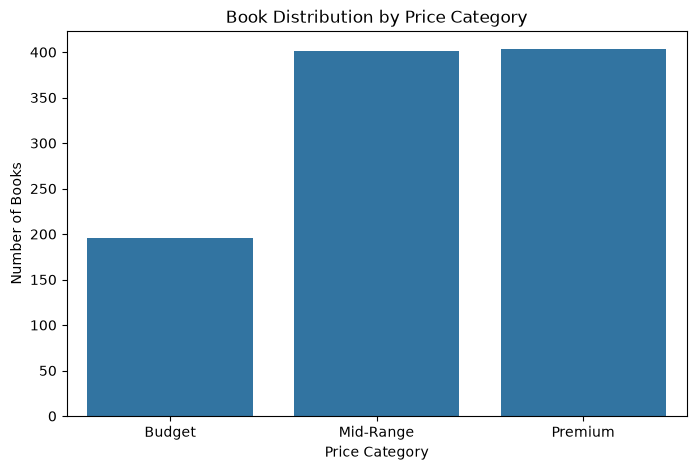

In [34]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x="Price_Category",
    data=cleaned_df,
    order=["Budget", "Mid-Range", "Premium"]
)

plt.title("Book Distribution by Price Category")
plt.xlabel("Price Category")
plt.ylabel("Number of Books")

plt.show()

# STEP 14 — Average Price by Rating

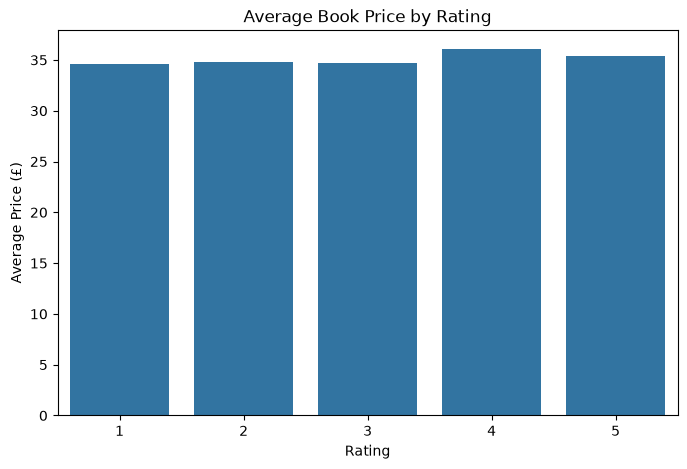

In [35]:
avg_price_rating = cleaned_df.groupby("Rating")["Price"].mean().reset_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    x="Rating",
    y="Price",
    data=avg_price_rating
)

plt.title("Average Book Price by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Price (£)")

plt.show()

# STEP 15 — Chart 5: Average Price by Price Category

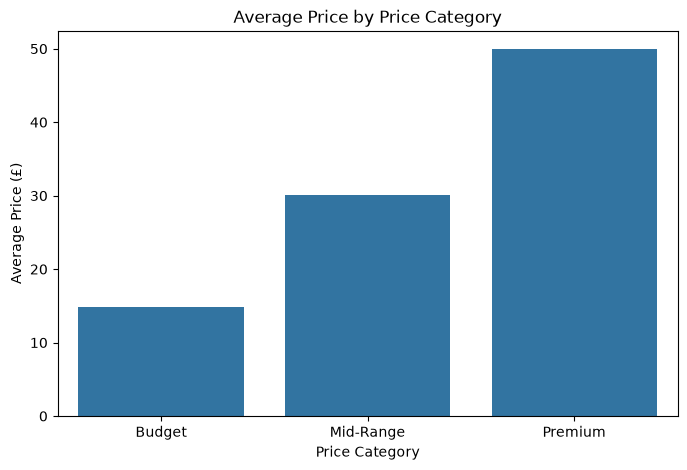

In [36]:
plt.figure(figsize=(8, 5))

avg_price_category = cleaned_df.groupby("Price_Category")["Price"].mean().reindex(
    ["Budget", "Mid-Range", "Premium"]
)

sns.barplot(
    x=avg_price_category.index,
    y=avg_price_category.values
)

plt.title("Average Price by Price Category")
plt.xlabel("Price Category")
plt.ylabel("Average Price (£)")

plt.show()

# STEP 16 — Chart 6: Availability Analysis 📦

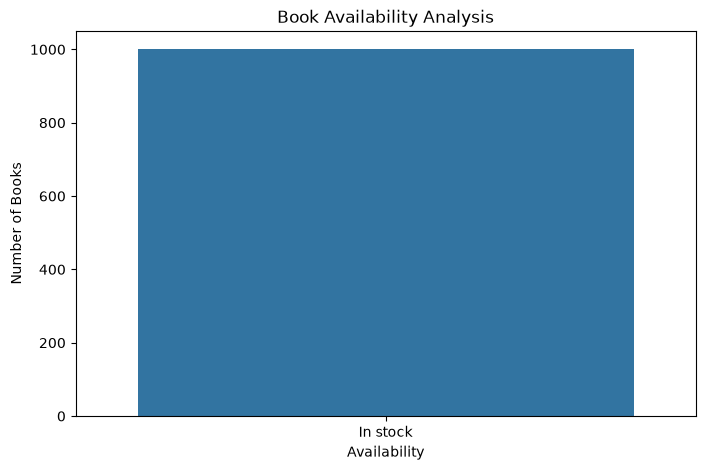

In [37]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x="Availability",
    data=cleaned_df
)

plt.title("Book Availability Analysis")
plt.xlabel("Availability")
plt.ylabel("Number of Books")

plt.show()

# STEP 17 — Chart 7: Rating vs Price 📈

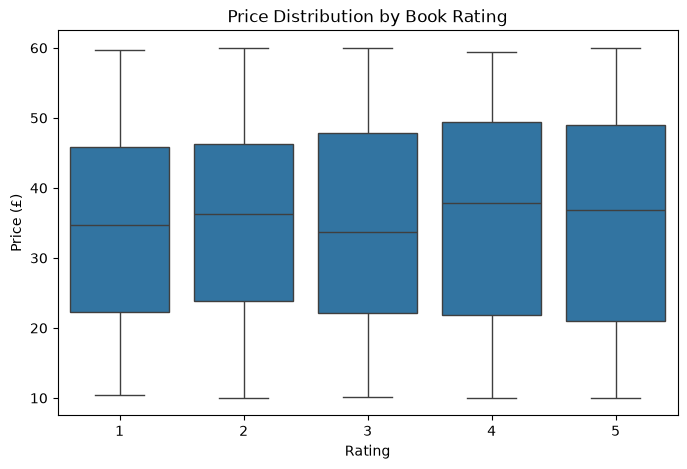

In [38]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Rating",
    y="Price",
    data=cleaned_df
)

plt.title("Price Distribution by Book Rating")
plt.xlabel("Rating")
plt.ylabel("Price (£)")

plt.show()

# STEP 18 — Chart 8: Price Category vs Rating Category

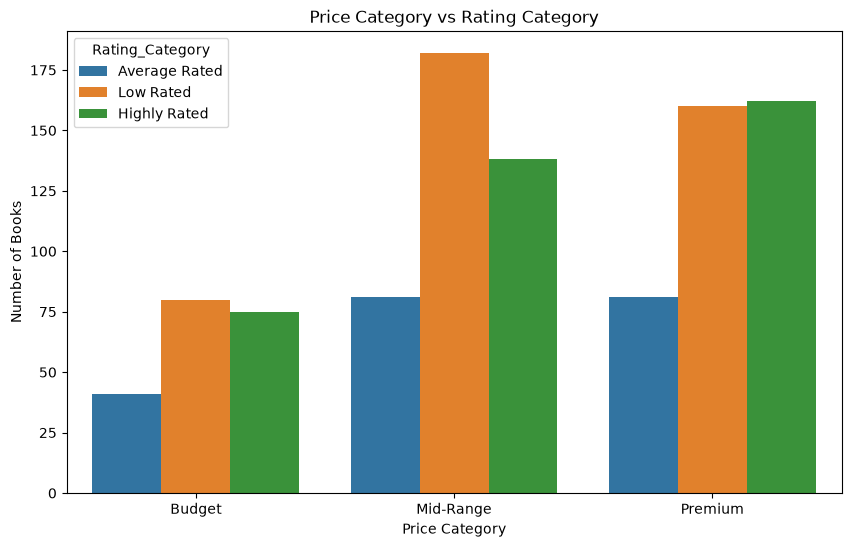

In [39]:
plt.figure(figsize=(10, 6))

sns.countplot(
    x="Price_Category",
    hue="Rating_Category",
    data=cleaned_df,
    order=["Budget", "Mid-Range", "Premium"]
)

plt.title("Price Category vs Rating Category")
plt.xlabel("Price Category")
plt.ylabel("Number of Books")

plt.show()

# Business Questions and Answers

Q1. What is the average book price?

In [40]:
print("Q1. Average Book Price:")
print(round(cleaned_df["Price"].mean(), 2))

Q1. Average Book Price:
35.07


Q2. Which rating has the highest number of books?

In [41]:
print("Q2. Most Common Rating:")
print(cleaned_df["Rating"].value_counts().idxmax())

Q2. Most Common Rating:
1


Q3. Which price category has the most books?

In [42]:
print("Q3. Most Common Price Category:")
print(cleaned_df["Price_Category"].value_counts().idxmax())

Q3. Most Common Price Category:
Premium


Q4. What is the most expensive book?

In [43]:
most_expensive = cleaned_df.loc[cleaned_df["Price"].idxmax()]

print("Q4. Most Expensive Book:")
print(most_expensive["Title"])
print("Price:", most_expensive["Price"])

Q4. Most Expensive Book:
The Perfect Play Play by Play 1
Price: 59.99


Q5. What is the cheapest book?

In [44]:
cheapest = cleaned_df.loc[cleaned_df["Price"].idxmin()]

print("Q5. Cheapest Book:")
print(cheapest["Title"])
print("Price:", cheapest["Price"])

Q5. Cheapest Book:
An Abundance of Katherines
Price: 10.0


Q6. Which rating has the highest average price?

In [45]:
avg_rating_price = cleaned_df.groupby("Rating")["Price"].mean()

print("Q6. Rating with Highest Average Price:")
print(avg_rating_price.idxmax())
print("Average Price:", round(avg_rating_price.max(), 2))

Q6. Rating with Highest Average Price:
4
Average Price: 36.09


Q7. How many books are highly rated?

In [46]:
print("Q7. Highly Rated Books:")
print((cleaned_df["Rating"] >= 4).sum())

Q7. Highly Rated Books:
375


Q8. How many books are in stock?

In [47]:
print("Q8. Books In Stock:")
print((cleaned_df["Availability"] == "In stock").sum())

Q8. Books In Stock:
1000


Q9. Which price category has the highest average rating?

In [48]:
avg_category_rating = cleaned_df.groupby("Price_Category")["Rating"].mean()

print("Q9. Price Category with Highest Average Rating:")
print(avg_category_rating.idxmax())
print("Average Rating:", round(avg_category_rating.max(), 2))

Q9. Price Category with Highest Average Rating:
Premium
Average Rating: 2.98


Q10. What is the relationship between price and rating?

In [49]:
correlation = cleaned_df["Price"].corr(cleaned_df["Rating"])

print("Q10. Price-Rating Correlation:")
print(round(correlation, 3))

Q10. Price-Rating Correlation:
0.028


# Business Insights

1. The dataset contains 1,000 books collected from the website.

2. Premium and Mid-Range books form the largest price categories, while Budget books are fewer.

3. Book ratings are distributed across all five rating levels.

4. The average book price is around the middle of the observed price range.

5. Average prices are very similar across different rating levels.

6. Premium books have the highest average rating among the price categories.

7. Book availability can be analyzed to understand the current stock position.

8. The price-rating correlation is 0.028, showing almost no relationship between price and rating.

# Business Recommendations

1. Maintain a balanced range of Budget, Mid-Range, and Premium books.

2. Focus on books with higher ratings because they can attract more customer interest.

3. Pricing should be based on market demand and book value rather than rating alone.

4. Monitor book availability regularly to avoid stock shortages.

5. Promote highly rated Premium and Mid-Range books to improve sales opportunities.